# D7: Model verbeteren
Vervolg op het hackathon-notebook uit D5/D6, met dezelfde dataset en dezelfde target.

**Verschil met de hackathon.** Daar werd op één train/test split geëvalueerd. Hier komt
daarbij: cross-validation met spreiding, een controle op overfitting door de trainscore
naast de testscore te leggen, en hyperparameters die systematisch worden doorzocht in
plaats van vastgezet.

**Maatkeuze.** Als zoekmaat gebruik ik PR-AUC in plaats van F1, omdat PR-AUC niet van een
vaste drempel afhangt en bij een scheve verdeling informatiever is dan ROC-AUC.

Voor de PR-AUC-keuze volg ik Saito en Rehmsmeier (2015), die laten zien dat de
precision-recall-curve bij scheve klassen informatiever is dan de ROC-curve.

### Indicatoren in dit notebook
| Indicator | Waar |
|---|---|
| **D2.1** Datakwaliteit, FAIR, ETL, toepasbaarheid | §0 |
| **D2.2** Analyse, visualisatie, algoritmes, reproduceerbaarheid | §1–§6 |
| **D2.3** Opkomende AI-toepassingen getoetst op de business case | §7 |
| **R1.1 / R1.3 / R2.1 / R3.3** Onderzoeksaanpak, kritische evaluatie, kader en bronvermelding | Top, §2, §6, §7, Literatuur |

### Wat ik uit D5/D6 meeneem
> **R1.1 – overzicht bijstellen:** de hackathon leverde drie open vragen op, die dit notebook stuurt:
> 1. Is de score van één testsplit betrouwbaar met maar 16 positieven? → cross-validation (§4)
> 2. Leert het forest de trainingsdata uit het hoofd? → train- vs. testscore (§4)
> 3. Waren de hyperparameters goed gekozen? → GridSearchCV (§2)
>
> Nieuw ten opzichte van D5/D6: een expliciete beoordeling van de data zelf (§0) en een
> verkenning van nieuwere AI-technieken (§7).

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, PrecisionRecallDisplay)

df = pd.read_excel("healthcare_provider_fraud_hackathon_pack.xlsx", sheet_name="Dataset")
y = (df["PotentialFraud"] == "Yes").astype(int)
num_kol = df.select_dtypes("number").columns.tolist()
cat_kol = ["Regio", "Specialisme"]
X = df[num_kol + cat_kol]

## 0. Datakwaliteit, herkomst en toepasbaarheid
> **Indicator D2.1:** voordat ik ga modelleren, beoordeel ik of de data geschikt is
> voor het doel: controles prioriteren.

**Kwaliteit.** 500 providers, geen duplicaten, en 8 tot 24 missende waarden in vijf kolommen
(zie D5/D6). Dat is beperkt, dus mediaanimputatie volstaat. Het label `PotentialFraud`
betekent "mogelijk onderzoek", niet bewezen fraude. Dat is het grootste kwaliteitsrisico:
het model leert eerdere selectiekeuzes na, inclusief eventuele bias daarin.

**FAIR-toets** (Wilkinson et al., 2016):
| Principe | Oordeel | Toelichting |
|---|---|---|
| Findable | Zwak | Geen persistente identifier of metadata, alleen een bestandsnaam |
| Accessible | Beperkt | Alleen beschikbaar via de cursusomgeving |
| Interoperable | Redelijk | Standaardformaat (xlsx), maar kolomnamen mengen Nederlands en Engels (`PotentialFraud`, `Specialisme`) en er is geen codeboek |
| Reusable | Zwak | Geen licentie, en niet gedocumenteerd hoe het label en de aggregaties tot stand kwamen |

**ETL in dit notebook.**
- *Extract:* inlezen van het werkblad `Dataset`.
- *Transform:* target omzetten naar 0/1 en `ProviderID` weglaten. Imputatie, schaling en
  one-hot-encoding gebeuren in een pipeline, zodat ze alleen op trainingsdata worden geleerd.
- *Load:* direct in het model, zonder tussenopslag.

In de praktijk ligt er een ETL-stap vóór deze dataset: van losse declaraties naar één rij
per provider. Die stap is hier niet zichtbaar, dus ik kan niet controleren hoe kenmerken als
`ClaimsPerPatient` berekend zijn.

**Toepasbaarheid.** De data is geschikt om een methode te ontwikkelen en te vergelijken,
niet om een model in productie te nemen. Ze is synthetisch, klein (64 positieven) en het
label is onzeker.

In [16]:
# D2.1: kwaliteitscontrole reproduceerbaar in dit notebook zelf
print("Vorm:", df.shape, "| dubbele providers:", df["ProviderID"].duplicated().sum())
print(df.isna().sum()[df.isna().sum() > 0])
print(df[num_kol].describe().T[["min", "max"]])   # onmogelijke waarden (negatief, >100%)?
import sklearn; print("scikit-learn", sklearn.__version__)  # versie vastleggen

Vorm: (500, 23) | dubbele providers: 0
Specialisme                               8
VergoedingsPercentage                    10
GemiddeldAantalChronischeAandoeningen    16
GemiddeldeLigduurDagen                   24
GemiddeldeDagenTotDeclaratie             12
dtype: int64
                                            min          max
AantalClaims                              45.00      8333.00
AantalUniekePatienten                     45.00      1348.00
ClaimsPerPatient                           0.80         9.79
GemiddeldClaimBedrag                      55.22      3956.59
TotaalClaimBedrag                      11173.73  11825709.17
GemiddeldeVergoeding                      37.30      2978.67
VergoedingsPercentage                     49.30        92.00
PercentageInpatientClaims                  0.00        62.50
PercentageOutpatientClaims                37.30       100.00
PercentageSpoedClaims                      0.00        23.30
GemiddeldeLeeftijdPatienten               22.80        80


## 1. Train/test split
Gestratificeerd, zodat train en test hetzelfde aandeel Yes bevatten. Vaste seed voor
reproduceerbaarheid. De voorbewerking zit in de pipeline, zodat mediaan en schaling alleen
op de trainset worden berekend.

> **Indicator D2.2 – reproduceerbaarheid:** vaste seeds voor split, folds en modellen.
> Iedereen die dit notebook draait, krijgt dezelfde getallen.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

print("Train:", len(y_train), "waarvan", y_train.sum(), "Yes")
print("Test :", len(y_test), "waarvan", y_test.sum(), "Yes")

voorbewerking = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_kol),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="Onbekend"),
                          OneHotEncoder(handle_unknown="ignore")), cat_kol),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Train: 375 waarvan 48 Yes
Test : 125 waarvan 16 Yes


## 2 en 4. Baseline en verbeteringen
Baseline: het random forest uit D6, ongewijzigd.
Verbetering 1: diepte handmatig beperkt. Een forest laat zijn bomen standaard volledig
doorgroeien, wat op 375 trainrijen met 48 Yes tot overfitting kan leiden.
Verbetering 2: GridSearchCV over vier hyperparameters, met vijfvoudige cross-validation.

> **Indicator D2.2 – algoritmes:** ik verbeter op twee manieren, eerst handmatig vanuit
> een hypothese (overfitting), dan systematisch. Zo zie ik of systematisch zoeken meer
> oplevert dan nadenken.

> **R2.1:** het beperken van de boomdiepte volgt uit de bias-variance-afweging: minder
> flexibiliteit geeft wat meer bias, maar minder variantie op een kleine dataset
> (Géron, 2022, hfst. 4).

In [10]:
baseline = make_pipeline(voorbewerking, RandomForestClassifier(
    n_estimators=300, min_samples_leaf=3,
    class_weight="balanced", random_state=42)).fit(X_train, y_train)

verb1 = make_pipeline(voorbewerking, RandomForestClassifier(
    n_estimators=300, max_depth=4, min_samples_leaf=5,
    class_weight="balanced", random_state=42)).fit(X_train, y_train)

rooster = {
    "randomforestclassifier__n_estimators":     [200, 400],
    "randomforestclassifier__max_depth":        [3, 5, 8, None],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5],
    "randomforestclassifier__class_weight":     ["balanced", None],
}
zoek = GridSearchCV(make_pipeline(voorbewerking, RandomForestClassifier(random_state=42)),
                    rooster, scoring="average_precision", cv=cv, n_jobs=-1).fit(X_train, y_train)

print("Beste instellingen:", {k.split("__")[1]: v for k, v in zoek.best_params_.items()})
print("Beste PR-AUC in cross-validation:", round(zoek.best_score_, 3))
verb2 = zoek.best_estimator_

Beste instellingen: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200}
Beste PR-AUC in cross-validation: 0.863


Een beslisboom en een SVM, beide met standaardinstellingen op één parameter na. Ze dienen
als vergelijking, niet als verbetering: ze laten zien of de prestatie uit het algoritme
komt of uit de data.

> **R2.1:** onderzoek naar tabeldata laat zien dat ensembles van bomen daar meestal beter
> presteren dan complexere modellen (Grinsztajn et al., 2022). De losse boom en de SVM
> toetsen of dat ook hier geldt.

In [11]:
boom = make_pipeline(voorbewerking, DecisionTreeClassifier(
    max_depth=4, class_weight="balanced", random_state=42)).fit(X_train, y_train)

svm = make_pipeline(voorbewerking, SVC(
    class_weight="balanced", probability=True, random_state=42)).fit(X_train, y_train)

C:\Users\vovan\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [12]:
modellen = {"Baseline (D5/D6)": baseline, "Verb. 1: max_depth=4": verb1,
            "Verb. 2: GridSearchCV": verb2, "Decision tree": boom, "SVM (RBF)": svm}

rijen, preds = [], {}
for naam, p in modellen.items():
    pred = p.predict(X_test)
    proba = p.predict_proba(X_test)[:, 1]
    preds[naam] = pred
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rijen.append({"model": naam,
                  "accuracy":    accuracy_score(y_test, pred),
                  "precision":   precision_score(y_test, pred, zero_division=0),
                  "recall":      recall_score(y_test, pred),
                  "specificity": tn / (tn + fp),
                  "f1":          f1_score(y_test, pred, zero_division=0),
                  "ROC-AUC":     roc_auc_score(y_test, proba),
                  "PR-AUC":      average_precision_score(y_test, proba)})

print("Basisrate:", round(y_test.mean(), 3))
pd.DataFrame(rijen).set_index("model").round(3)

Basisrate: 0.128


,accuracy,precision,recall,specificity,f1,ROC-AUC,PR-AUC
model,,,,,,,
Baseline (D5/D6),0.960,0.867,0.812,0.982,0.839,0.915,0.891
Verb. 1: max_depth=4,0.960,0.867,0.812,0.982,0.839,0.912,0.890
Verb. 2: GridSearchCV,0.968,1.000,0.750,1.000,0.857,0.913,0.893
Decision tree,0.888,0.550,0.688,0.917,0.611,0.806,0.626
SVM (RBF),0.976,0.933,0.875,0.991,0.903,0.962,0.922


De testset bevat weinig positieven, dus één testscore is onzeker. Cross-validation geeft
vijf scores en daarmee een spreiding. Het verschil tussen train- en testscore laat zien
of een model de trainingsdata uit het hoofd leert.

In [13]:
print("Cross-validation op de trainset (PR-AUC, 5 folds):")
for naam, p in modellen.items():
    s = cross_val_score(p, X_train, y_train, cv=cv, scoring="average_precision")
    print(f"  {naam:24s} {s.mean():.3f}  (spreiding {s.std():.3f})")

print("\nOverfitting (PR-AUC op train tegen test):")
for naam, p in modellen.items():
    tr = average_precision_score(y_train, p.predict_proba(X_train)[:, 1])
    te = average_precision_score(y_test,  p.predict_proba(X_test)[:, 1])
    print(f"  {naam:24s} train {tr:.3f}  test {te:.3f}  verschil {tr - te:+.3f}")

Cross-validation op de trainset (PR-AUC, 5 folds):
  Baseline (D5/D6)         0.858  (spreiding 0.069)
  Verb. 1: max_depth=4     0.852  (spreiding 0.066)
  Verb. 2: GridSearchCV    0.863  (spreiding 0.092)
  Decision tree            0.567  (spreiding 0.157)


C:\Users\vovan\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\vovan\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\vovan\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\vovan\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\sklearn\svm\_base.py:236: Fu

  SVM (RBF)                0.849  (spreiding 0.076)

Overfitting (PR-AUC op train tegen test):
  Baseline (D5/D6)         train 1.000  test 0.891  verschil +0.109
  Verb. 1: max_depth=4     train 0.966  test 0.890  verschil +0.075
  Verb. 2: GridSearchCV    train 1.000  test 0.893  verschil +0.107
  Decision tree            train 0.929  test 0.626  verschil +0.304
  SVM (RBF)                train 0.994  test 0.922  verschil +0.072


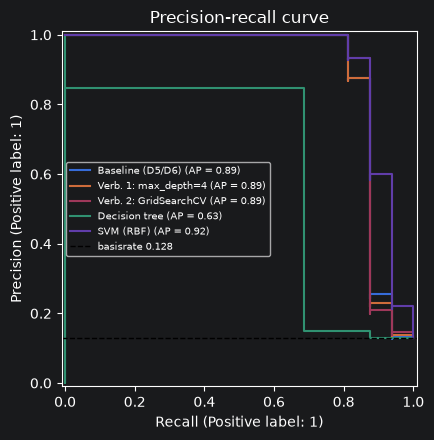

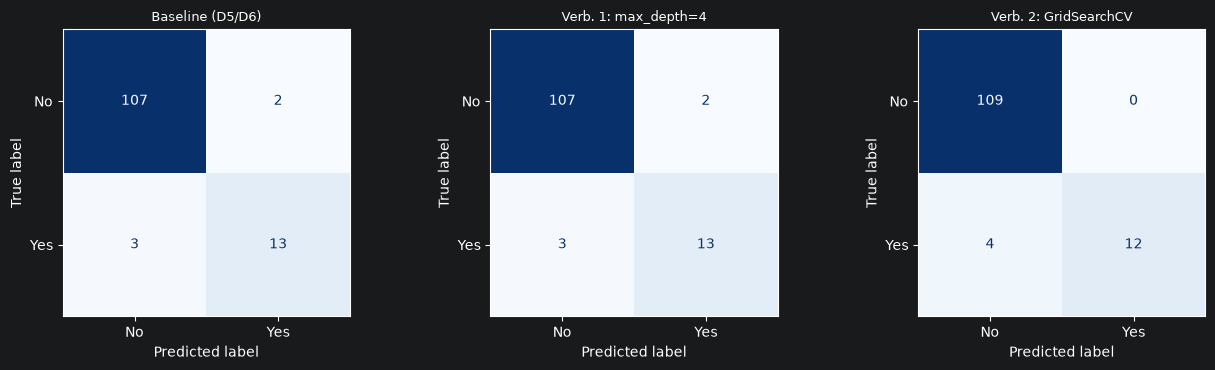

In [14]:
basisrate = y_test.mean()
fig, as_ = plt.subplots(figsize=(6.5, 4.5))
for naam, p in modellen.items():
    PrecisionRecallDisplay.from_estimator(p, X_test, y_test, ax=as_, name=naam)
as_.axhline(basisrate, ls="--", c="k", lw=1, label=f"basisrate {basisrate:.3f}")
as_.set_title("Precision-recall curve")
as_.legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, assen = plt.subplots(1, 3, figsize=(13, 3.8))
for a, naam in zip(assen, ["Baseline (D5/D6)", "Verb. 1: max_depth=4", "Verb. 2: GridSearchCV"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[naam]),
                           display_labels=["No", "Yes"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(naam, fontsize=9)
plt.tight_layout()
plt.show()

## 6. Conclusie

**Testset.** Baseline en verbetering 1 scoren identiek: 13 van de 16 gevonden, 2 onterechte
signaleringen. Verbetering 2 ruilt recall in voor precision (12 gevonden, geen onterechte).
De F1 stijgt daardoor, maar er wordt een risicoprovider extra gemist. Voor dit doel is dat
geen vooruitgang.

**Cross-validation.** De vier bruikbare modellen liggen tussen 0,849 en 0,863 PR-AUC. De
spreiding over de folds bedraagt 0,066 tot 0,092, vijf keer het onderlinge verschil. De
rangorde op de testset is dus niet hard.

**Overfitting.** Baseline en verbetering 2 halen beide PR-AUC 1,000 op de trainset tegen
circa 0,89 op de testset. Verbetering 1 komt op 0,966 tegen 0,890: dezelfde testprestatie,
kleiner gat, dus robuuster. GridSearchCV koos juist méér flexibiliteit (max_depth=8) en
belandde ook op 1,000. Optimaliseren op PR-AUC beschermt dus niet tegen overfitting.

**Vergelijkingsmodellen.** De losse beslisboom scoort het slechtst (PR-AUC 0,626) en
overfit het sterkst (+0,304); de prestatie van het forest komt dus uit het ensemble. Zijn
ROC-AUC is 0,806 tegenover een PR-AUC van 0,626, wat laat zien dat ROC-AUC bij een scheve
verdeling vleit. De SVM scoort op de testset op elke maat het hoogst (F1 0,903, PR-AUC
0,922) met het kleinste overfit-gat, maar in de cross-validation juist het laagst (0,849).

**Keuze.** Verbetering 1, bij gelijke testprestatie minder afhankelijk van de trainingsdata.
De SVM is een serieuze kandidaat, maar de cross-validation onderbouwt dat niet.

**Kritische kanttekening.**
> **R1.3 – evalueren en nuanceren:** de CV-score van GridSearchCV (0,863) is te optimistisch.
> Dezelfde folds zijn gebruikt om de beste instellingen te kiezen en om die keuze te
> beoordelen. Cawley en Talbot (2010) noemen dit selectiebias. Een eerlijke schatting
> vraagt nested cross-validation. Dat de SVM op de testset wint maar in cross-validation
> verliest, bevestigt dat één testsplit met 16 positieven geen harde rangorde geeft.

**Beperking.** Met 16 positieven verschuift één provider de recall al ruim zes procentpunt.
Alle verschillen vallen binnen die marge.

## 7. Opkomende AI-toepassingen voor fraudedetectie
> **Indicator D2.3:** ik verken vijf ontwikkelingen uit de literatuur en toets elke
> ontwikkeling aan deze business case: kleine, gelabelde tabeldata, met het doel controles
> te prioriteren en een medewerker die de eindbeslissing neemt.

| Ontwikkeling | Bruikbaar hier? | Kans | Uitdaging |
|---|---|---|---|
| **Gradient boosting** (Chen & Guestrin, 2016) | Ja, direct | Vaak de sterkste methode op tabeldata (Grinsztajn et al., 2022) | Meer hyperparameters; overfit snel bij 48 positieven in de trainset |
| **Explainable AI / SHAP** (Lundberg & Lee, 2017) | Ja, en het meest nodig | Geeft per provider aan *waarom* die gesignaleerd wordt; ondersteunt de controleur | Uitleg toont correlatie, niet oorzaak; kan schijnzekerheid geven |
| **Anomaliedetectie**, bv. Isolation Forest (Liu et al., 2008) | Ja, als aanvulling | Werkt zonder label, dus omzeilt het onzekere label `PotentialFraud`; vindt ook nieuwe fraudepatronen | Afwijkend is niet frauduleus; meer fout-positieven |
| **Graafmodellen** (netwerken van providers en patiënten) | Nee, niet met deze data | Fraude gebeurt vaak in netwerken | Vereist relaties tussen providers en patiënten; deze dataset heeft één rij per provider |
| **Generatieve AI / LLM's** | Nee, voorlopig niet | Zou vrije tekst in declaraties of dossiers kunnen analyseren | Geen tekstdata hier; privacy van medische gegevens; hallucinaties |

**Impact en randvoorwaarden.** Een systeem dat zorgaanbieders selecteert voor controle,
raakt aan regelgeving. De AVG beperkt besluiten die uitsluitend geautomatiseerd tot stand
komen (art. 22). De EU AI Act (Verordening 2024/1689) stelt extra eisen aan AI-systemen
met een hoog risico. Deze verordening is in 2026 gewijzigd (Verordening 2026/1744). Of
deze toepassing als hoog risico geldt, moet juridisch getoetst worden. Mijn advies, "mens
beslist, model prioriteert", sluit hierop aan.

**Conclusie voor de business case.** De eerstvolgende stap is SHAP toevoegen aan het
gekozen forest, omdat uitlegbaarheid hier zwaarder weegt dan een paar procentpunt extra
PR-AUC. Anomaliedetectie is de tweede stap, als vangnet voor fraude die niet op eerdere
labels lijkt.

## Literatuur
> **R3.3:** alle bronnen in APA 7; elke verwijzing in de tekst staat in deze lijst en omgekeerd.

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent
selection bias in performance evaluation. *Journal of Machine Learning Research, 11*(70),
2079–2107.

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of
the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*
(pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow*
(3rd ed.). O'Reilly.

Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still
outperform deep learning on typical tabular data? *Advances in Neural Information
Processing Systems, 35* (Datasets and Benchmarks Track).
https://doi.org/10.48550/arXiv.2207.08815

Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation forest. In *2008 Eighth IEEE
International Conference on Data Mining* (pp. 413–422). IEEE.
https://doi.org/10.1109/ICDM.2008.17

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions.
*Advances in Neural Information Processing Systems, 30*, 4765–4774.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the
ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3),
e0118432. https://doi.org/10.1371/journal.pone.0118432

Verordening (EU) 2016/679 van het Europees Parlement en de Raad van 27 april 2016
betreffende de bescherming van natuurlijke personen in verband met de verwerking van
persoonsgegevens en betreffende het vrije verkeer van die gegevens (Algemene verordening
gegevensbescherming). (2016). *Publicatieblad van de Europese Unie*, L 119, 1–88.

Verordening (EU) 2024/1689 van het Europees Parlement en de Raad van 13 juni 2024 tot
vaststelling van geharmoniseerde regels betreffende artificiële intelligentie (verordening
artificiële intelligentie). (2024). *Publicatieblad van de Europese Unie*, L 2024/1689.
http://data.europa.eu/eli/reg/2024/1689/oj

Verordening (EU) 2026/1744 van het Europees Parlement en de Raad van 8 juli 2026 tot
wijziging van de Verordeningen (EU) 2024/1689, (EU) 2018/1139 en (EU) 2023/1230 wat betreft
vereenvoudiging van de uitvoering van geharmoniseerde regels betreffende artificiële
intelligentie. (2026). *Publicatieblad van de Europese Unie*, L 2026/1744.

Wilkinson, M. D., Dumontier, M., Aalbersberg, I. J., Appleton, G., Axton, M., Baak, A.,
Blomberg, N., Boiten, J.-W., da Silva Santos, L. B., Bourne, P. E., Bouwman, J.,
Brookes, A. J., Clark, T., Crosas, M., Dillo, I., Dumon, O., Edmunds, S., Evelo, C. T.,
Finkers, R., ... Mons, B. (2016). The FAIR Guiding Principles for scientific data
management and stewardship. *Scientific Data, 3*(1), 160018.
https://doi.org/10.1038/sdata.2016.18